In [14]:
## Sales & Demand Forecasting for Businesses

In [15]:
import pandas as pd

In [17]:
sales_data = pd.read_csv("data/Sample - Superstore.csv", encoding="latin1")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

sales_data.head(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820


In [18]:
#Dataset size and structure
sales_data.shape
sales_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [19]:
# Order date should be datetime, not object
sales_data["Order Date"] = pd.to_datetime(sales_data["Order Date"])


In [20]:
# Dataset time period
print(sales_data["Order Date"].min())
print(sales_data["Order Date"].max())
print(sales_data["Order Date"].nunique())


2014-01-03 00:00:00
2017-12-30 00:00:00
1237


In [21]:
# Dataset period and number of unique order dates
print((sales_data["Order Date"].max() - sales_data["Order Date"].min()).days + 1)
print(sales_data["Order Date"].nunique())

1458
1237


In [22]:
# Transactions per year
sales_data["Order Date"].dt.year.value_counts().sort_index()

Order Date
2014    1993
2015    2102
2016    2587
2017    3312
Name: count, dtype: int64

In [23]:
#Sales made each year
sales_data.groupby(sales_data["Order Date"].dt.year)["Sales"].sum()

Order Date
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

In [72]:
#Monthly sales
monthly_sales  = sales_data.groupby(sales_data["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly_sales

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


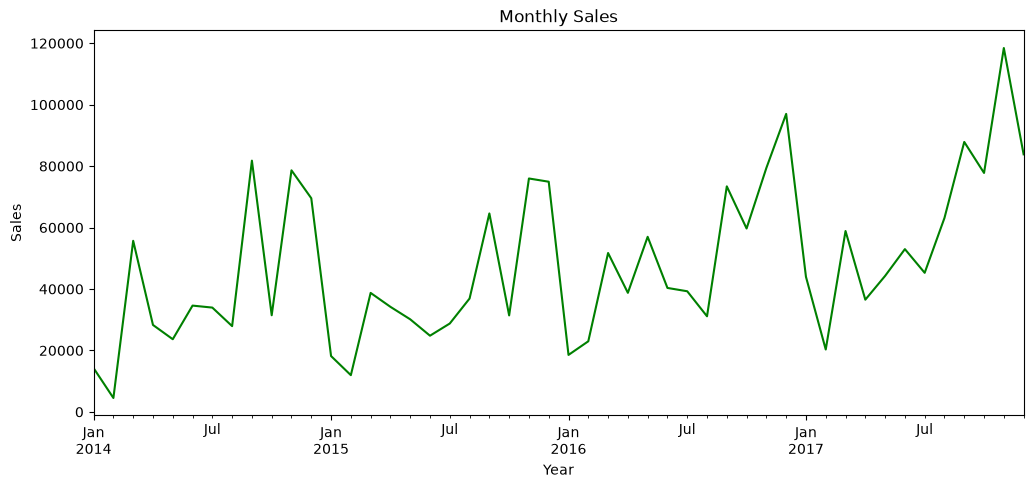

In [73]:
# Visualizing the findings
from matplotlib import pyplot as plt

monthly_sales.plot(figsize=(12,5), color="green")
plt.title("Monthly Sales")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()


In [71]:
#Average monthly sales across all the 4 years
monthly_avg = monthly_sales.groupby(monthly_sales.index.month).mean()
monthly_avg



Order Date
1     23731.208900
2     14937.812850
3     51251.372200
4     34440.532150
5     38757.202925
6     38179.669825
7     36809.524250
8     39761.015750
9     76912.486425
10    50080.746175
11    88115.267750
12    81323.375875
Name: Sales, dtype: float64

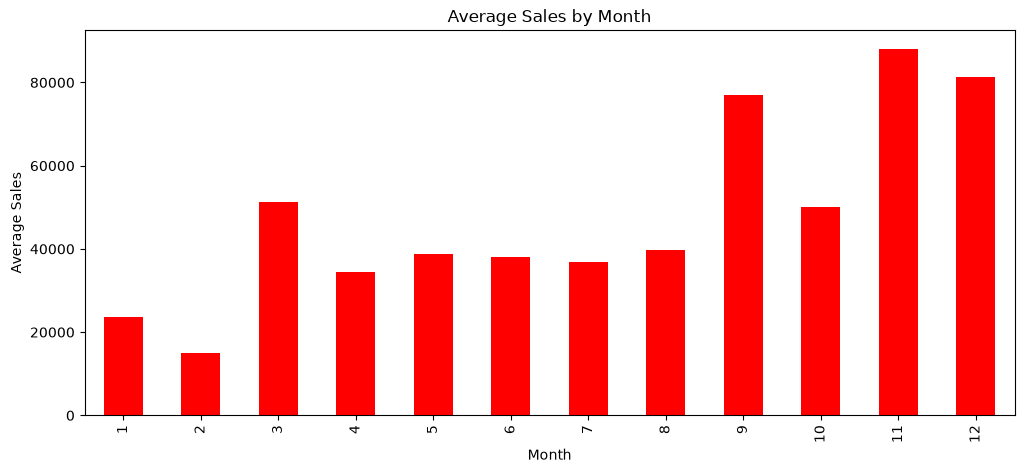

In [27]:
#Visualizing average monthly sales across all the 4 years
monthly_avg.plot(figsize=(12, 5), color="red", kind="bar")
plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.show()


In [28]:
#Comparing each month's average sales with the overall monthly average
monthly_sales.mean()

np.float64(47858.35125625)

In [29]:
#Creating year column/feature.
sales_data["Year"] = sales_data["Order Date"].dt.year
sales_data[["Order Date", "Year"]].head()



,Order Date,Year
0,2016-11-08,2016
1,2016-11-08,2016
2,2016-06-12,2016
3,2015-10-11,2015
4,2015-10-11,2015


In [30]:
#Month feature/column
sales_data["Month"] = sales_data["Order Date"].dt.month
sales_data[["Order Date", "Month"]].head()

,Order Date,Month
0,2016-11-08,11
1,2016-11-08,11
2,2016-06-12,6
3,2015-10-11,10
4,2015-10-11,10


In [31]:
#Converting to Monthy sales observations'

monthly_df = monthly_sales.reset_index()
monthly_df


,Order Date,Sales
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


In [32]:
monthly_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype    
---  ------      --------------  -----    
 0   Order Date  48 non-null     period[M]
 1   Sales       48 non-null     float64  
dtypes: float64(1), period[M](1)
memory usage: 900.0 bytes


In [33]:
monthly_df["Year"] = monthly_df["Order Date"].dt.year
monthly_df["Month"] = monthly_df["Order Date"].dt.month

In [34]:
monthly_df.head()

,Order Date,Sales,Year,Month
0,2014-01,14236.895,2014,1
1,2014-02,4519.892,2014,2
2,2014-03,55691.009,2014,3
3,2014-04,28295.345,2014,4
4,2014-05,23648.287,2014,5


In [35]:
print(monthly_df["Year"].unique())

[2014 2015 2016 2017]


In [36]:
#Number of observations per yr
print(monthly_df["Year"].value_counts().sort_index())

Year
2014    12
2015    12
2016    12
2017    12
Name: count, dtype: int64


In [37]:
print(monthly_df.tail())

   Order Date        Sales  Year  Month
43    2017-08   63120.8880  2017      8
44    2017-09   87866.6520  2017      9
45    2017-10   77776.9232  2017     10
46    2017-11  118447.8250  2017     11
47    2017-12   83829.3188  2017     12


In [38]:
#Training data
train_data = monthly_df[monthly_df["Year"] <=2016]
test_data =  monthly_df[monthly_df["Year"] == 2017]

In [39]:
#checking on shape
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (36, 4)
Testing data: (12, 4)


In [40]:
#Min and Max Dates for each dataset
print("Training period: ", train_data["Order Date"].min(), "to", train_data["Order Date"].max())
print("Testing period: ", test_data["Order Date"].min(), "to", test_data["Order Date"].max())

Training period:  2014-01 to 2016-12
Testing period:  2017-01 to 2017-12


In [41]:
X_train  = train_data[["Year", "Month"]]
y_train = train_data["Sales"]

X_test = test_data[["Year", "Month"]]
y_test = test_data["Sales"]


print(X_train.head())
print(y_train.head())
print(X_test.head())
print(y_test.head())

   Year  Month
0  2014      1
1  2014      2
2  2014      3
3  2014      4
4  2014      5
0    14236.895
1     4519.892
2    55691.009
3    28295.345
4    23648.287
Name: Sales, dtype: float64
    Year  Month
36  2017      1
37  2017      2
38  2017      3
39  2017      4
40  2017      5
36    43971.3740
37    20301.1334
38    58872.3528
39    36521.5361
40    44261.1102
Name: Sales, dtype: float64


In [42]:
#Used linear reg
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

#Actual sales vs predicted (2017)
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(comparison)

         Actual     Predicted
36   43971.3740  26729.057793
37   20301.1334  31661.450844
38   58872.3528  36593.843896
39   36521.5361  41526.236948
40   44261.1102  46458.630000
41   52981.7257  51391.023052
42   45264.4160  56323.416104
43   63120.8880  61255.809156
44   87866.6520  66188.202207
45   77776.9232  71120.595259
46  118447.8250  76052.988311
47   83829.3188  80985.381363


In [43]:
from sklearn.metrics import mean_absolute_error

mae =mean_absolute_error(y_test, y_pred)
print(mae)



12180.97472158754


In [44]:
#enc.
monthly_model = monthly_df.copy()
print(monthly_model.head())

  Order Date      Sales  Year  Month
0    2014-01  14236.895  2014      1
1    2014-02   4519.892  2014      2
2    2014-03  55691.009  2014      3
3    2014-04  28295.345  2014      4
4    2014-05  23648.287  2014      5


In [45]:
monthly_model = pd.get_dummies(
    monthly_model,
    columns=["Month"],
    prefix = "Month"
)

monthly_model.head()

,Order Date,Sales,Year,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
0,2014-01,14236.895,2014,True,False,False,False,False,False,False,False,False,False,False,False
1,2014-02,4519.892,2014,False,True,False,False,False,False,False,False,False,False,False,False
2,2014-03,55691.009,2014,False,False,True,False,False,False,False,False,False,False,False,False
3,2014-04,28295.345,2014,False,False,False,True,False,False,False,False,False,False,False,False
4,2014-05,23648.287,2014,False,False,False,False,True,False,False,False,False,False,False,False


In [46]:
print(monthly_model.columns)

Index(['Order Date', 'Sales', 'Year', 'Month_1', 'Month_2', 'Month_3',
       'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9',
       'Month_10', 'Month_11', 'Month_12'],
      dtype='str')


In [47]:
X=monthly_model[['Year', 'Month_1', 'Month_2', 'Month_3',
       'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9',
       'Month_10', 'Month_11', 'Month_12']]

y=monthly_model['Sales']

In [48]:
train = monthly_model[monthly_model["Year"] <= 2016]
test = monthly_model[monthly_model["Year"] == 2017]

In [49]:
X_train = train[['Year', 'Month_1', 'Month_2', 'Month_3',
       'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9',
       'Month_10', 'Month_11', 'Month_12']]
y_train = train["Sales"]

X_test = test[['Year','Month_1', 'Month_2', 'Month_3',
       'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9',
       'Month_10', 'Month_11', 'Month_12']]
y_test = test["Sales"]


print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(36, 13)
(36,)
(12, 13)
(12,)


In [50]:
#training monthly model
from sklearn.linear_model import LinearRegression

seasonal_model = LinearRegression()

seasonal_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 5206.59,-26459.56,-30294.01,..., -2595.36, 34560.37, 37044.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['Year','Month_1','Month_2',...,'Month_10','Month_11','Month_12']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.045e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [51]:
y_pred_seasonal = seasonal_model.predict(X_test)
print(y_pred_seasonal)

[27397.66219167 23563.214325   59124.220325   44160.03915833
 47335.74215833 43658.82619167 44404.40199167 42387.56665833
 83674.27289167 51261.86215833 88417.590325   90901.23655833]


In [52]:
from sklearn.metrics import mean_absolute_error

mae_seasonal = mean_absolute_error(y_test, y_pred_seasonal)
mae_seasonal

10793.885226388707

In [53]:
print(y_pred)
print(y_pred_seasonal)

[26729.05779252 31661.45084439 36593.84389625 41526.23694812
 46458.62999998 51391.02305185 56323.41610371 61255.80915558
 66188.20220744 71120.59525931 76052.98831117 80985.38136303]
[27397.66219167 23563.214325   59124.220325   44160.03915833
 47335.74215833 43658.82619167 44404.40199167 42387.56665833
 83674.27289167 51261.86215833 88417.590325   90901.23655833]


In [54]:
print(y_pred == y_pred_seasonal)

[False False False False False False False False False False False False]


In [55]:
#direct comparison
comparison = pd.DataFrame({
    "Actual": y_test,
    "Baseline_Predicted": y_pred,
    "Seasonal_Predicted": y_pred_seasonal
})

print(comparison)

         Actual  Baseline_Predicted  Seasonal_Predicted
36   43971.3740        26729.057793        27397.662192
37   20301.1334        31661.450844        23563.214325
38   58872.3528        36593.843896        59124.220325
39   36521.5361        41526.236948        44160.039158
40   44261.1102        46458.630000        47335.742158
41   52981.7257        51391.023052        43658.826192
42   45264.4160        56323.416104        44404.401992
43   63120.8880        61255.809156        42387.566658
44   87866.6520        66188.202207        83674.272892
45   77776.9232        71120.595259        51261.862158
46  118447.8250        76052.988311        88417.590325
47   83829.3188        80985.381363        90901.236558


In [56]:
#Absolute error for each model

comparison["Baseline_Error"] = abs(
    comparison["Actual"] - comparison["Baseline_Predicted"]
)

comparison["Seasonal_Error"] = abs(
    comparison["Actual"] - comparison["Seasonal_Predicted"]
)

print(comparison)

         Actual  Baseline_Predicted  Seasonal_Predicted  Baseline_Error  \
36   43971.3740        26729.057793        27397.662192    17242.316207   
37   20301.1334        31661.450844        23563.214325    11360.317444   
38   58872.3528        36593.843896        59124.220325    22278.508904   
39   36521.5361        41526.236948        44160.039158     5004.700848   
40   44261.1102        46458.630000        47335.742158     2197.519800   
41   52981.7257        51391.023052        43658.826192     1590.702648   
42   45264.4160        56323.416104        44404.401992    11059.000104   
43   63120.8880        61255.809156        42387.566658     1865.078844   
44   87866.6520        66188.202207        83674.272892    21678.449793   
45   77776.9232        71120.595259        51261.862158     6656.327941   
46  118447.8250        76052.988311        88417.590325    42394.836689   
47   83829.3188        80985.381363        90901.236558     2843.937437   

    Seasonal_Error  
36 

In [74]:
monthly_model = pd.get_dummies(
    monthly_df,
    columns=["Month"],
    prefix="Month",
    drop_first=True
)

print(monthly_model)
print(monthly_model.columns)

   Order Date        Sales  Year        Lag_1  Month_2  Month_3  Month_4  \
1     2014-02    4519.8920  2014   14236.8950     True    False    False   
2     2014-03   55691.0090  2014    4519.8920    False     True    False   
3     2014-04   28295.3450  2014   55691.0090    False    False     True   
4     2014-05   23648.2870  2014   28295.3450    False    False    False   
5     2014-06   34595.1276  2014   23648.2870    False    False    False   
6     2014-07   33946.3930  2014   34595.1276    False    False    False   
7     2014-08   27909.4685  2014   33946.3930    False    False    False   
8     2014-09   81777.3508  2014   27909.4685    False    False    False   
9     2014-10   31453.3930  2014   81777.3508    False    False    False   
10    2014-11   78628.7167  2014   31453.3930    False    False    False   
11    2014-12   69545.6205  2014   78628.7167    False    False    False   
12    2015-01   18174.0756  2015   69545.6205    False    False    False   
13    2015-0

In [59]:
#X and y  for cleaned seasonal model
train = monthly_model[monthly_model["Year"] <= 2016]
test = monthly_model[monthly_model["Year"] == 2017]

X_train = train.drop(columns=["Order Date", "Sales"])
y_train = train["Sales"]

X_test = test.drop(columns=["Order Date", "Sales"])
y_test = test["Sales"]

print(X_train.shape)
print(X_test.shape)

(36, 12)
(12, 12)


In [60]:
#retraining cleaned seasonal model
from sklearn.linear_model import LinearRegression

seasonal_model = LinearRegression()
seasonal_model.fit(X_train, y_train)
y_pred_seasonal = seasonal_model.predict(X_test)


from sklearn.metrics import mean_absolute_error
mae_seasonal = mean_absolute_error(y_test, y_pred_seasonal)
print(mae_seasonal)

10793.885226388707


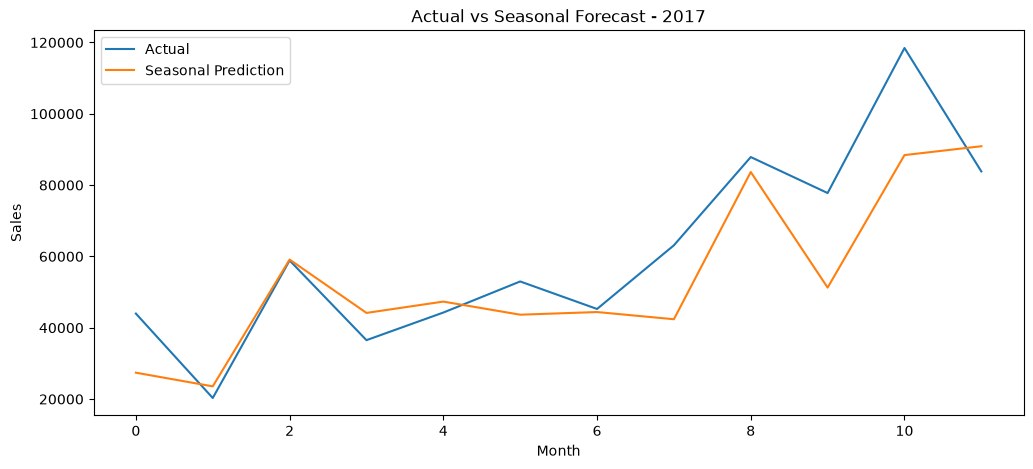

In [61]:
#act vs seasonal forecast graph

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred_seasonal, label="Seasonal Prediction")

plt.title("Actual vs Seasonal Forecast - 2017")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()

plt.show()

In [62]:
#using lags feature

monthly_df["Lag_1"] = monthly_df["Sales"].shift(1)
print(monthly_df[["Order Date", "Sales", "Lag_1"]].head())
print(monthly_df[["Sales", "Lag_1"]].corr())

  Order Date      Sales      Lag_1
0    2014-01  14236.895        NaN
1    2014-02   4519.892  14236.895
2    2014-03  55691.009   4519.892
3    2014-04  28295.345  55691.009
4    2014-05  23648.287  28295.345
          Sales     Lag_1
Sales  1.000000  0.376481
Lag_1  0.376481  1.000000


In [63]:
monthly_df = monthly_df.dropna()
print(monthly_df.shape)

(47, 5)


In [64]:
train = monthly_df[monthly_df["Year"] <= 2016]
test = monthly_df[monthly_df["Year"] == 2017]

X_train =  train[["Lag_1"]]
y_train = train["Sales"]

X_test = test[["Lag_1"]]
y_test = test["Sales"]


In [65]:
from sklearn.linear_model import LinearRegression

lag_model = LinearRegression()

lag_model.fit(X_train, y_train)

y_pred_lag = lag_model.predict(X_test)
print(y_pred_lag)

[58231.41990343 44799.68553069 38804.09133857 48574.05451408
 42912.6660618  44873.07475842 47081.97801915 45127.20882191
 49650.19452468 55918.21526115 53362.52009879 63664.3259292 ]


In [66]:
from sklearn.metrics import mean_absolute_error
mae_lag = mean_absolute_error(y_test, y_pred_lag)
print(f"The MAE for LAG model is : {mae_lag}")

The MAE for LAG model is : 20456.098114402645


In [67]:
#Opted for the seasonal model since it has the lowest MAE

final_forecast = pd.DataFrame({
    "Month": test["Month"],
    "Actual_Sales": y_test.values,
    "Forecast_Sales": y_pred_seasonal
})

final_forecast

,Month,Actual_Sales,Forecast_Sales
36,1,43971.3740,27397.662192
37,2,20301.1334,23563.214325
38,3,58872.3528,59124.220325
39,4,36521.5361,44160.039158
40,5,44261.1102,47335.742158
41,6,52981.7257,43658.826192
42,7,45264.4160,44404.401992
43,8,63120.8880,42387.566658
44,9,87866.6520,83674.272892
45,10,77776.9232,51261.862158


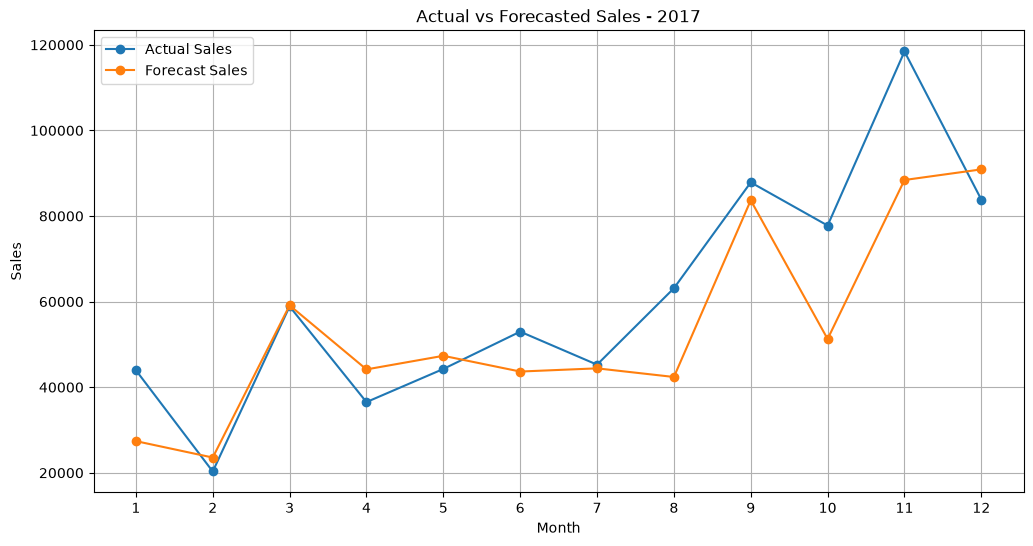

In [68]:
plt.figure(figsize=(12, 6))

plt.plot(
    final_forecast["Month"],
    final_forecast["Actual_Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    final_forecast["Month"],
    final_forecast["Forecast_Sales"],
    marker="o",
    label="Forecast Sales"
)

plt.title("Actual vs Forecasted Sales - 2017")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#Business Insights:

"""
a) Sales show a clear upward trend over the years.
Annual sales increased from about $484K in 2014 to $733K in 2017. Overall, this shows that sales grew significantly over the four-year period.

b) Sales vary depending on the month.
February is usually one of the lower-sales months, while September, November, and December tend to record higher sales. 
This shows that there is a noticeable seasonal pattern in the data.

c) The seasonal model performed better than the baseline model.
The seasonal model reduced the MAE from 12,180.97 to 10,793.89, which is about an 11.4% improvement on the 2017 test data. 
This suggests that including monthly patterns helped the model make better predictions.

d) The model captures general patterns, but it can miss large sales spikes.
For example, actual sales in November 2017 were about $118,448, while the model forecasted about $88,418. 
This shows that the model can follow the general seasonal pattern but may not capture unusual increases in sales.

e) The forecast can be useful for general business planning.
The identified seasonal patterns could support general planning for inventory, staffing, budgeting, and other operations. 
However, the forecast is an estimate and should be used as one input in planning rather than treated as an exact prediction.
"""